question 12: Video Action Recognition using I3D: Implement or use a pretrained I3D or SlowFast model to classify actions in videos (e.g., UCF101). Analyze temporal features. 

Defaulting to user installation because normal site-packages is not writeable
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for pytorchvideo: filename=pytorchvideo-0.1.5-py3-none-any.whl size=188756 sha256=c60442c6c7088fe206d72c5624c4baeeb41ef1b17cefb3ddd537dbea72254852
  Stored in directory: /home/cse2k26/cse2k2652/.cache/pip/wheels/e0/85/41/42153f93cd5715669b2fd7765b25cfca52c7277ad5a6762112
Successfully built pytorchvideo
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pytorchvideo] [pytorchvideo]
Using device: cpu
Downloading: "https://github.com/facebookresearch/pytorchvideo/zipball/main" to /home/cse2k26/cse2k2652/.cache/torch/hub/main.zip
Downloading: "https://dl.fbaipublicfiles.com/p

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 264M/264M [00:07<00:00, 35.8MB/s]



================== TOP-5 PREDICTIONS ==================
1. archery: 100.00%
2. "disc golfing": 0.00%
3. "throwing axe": 0.00%
4. "golf driving": 0.00%
5. "front raises": 0.00%


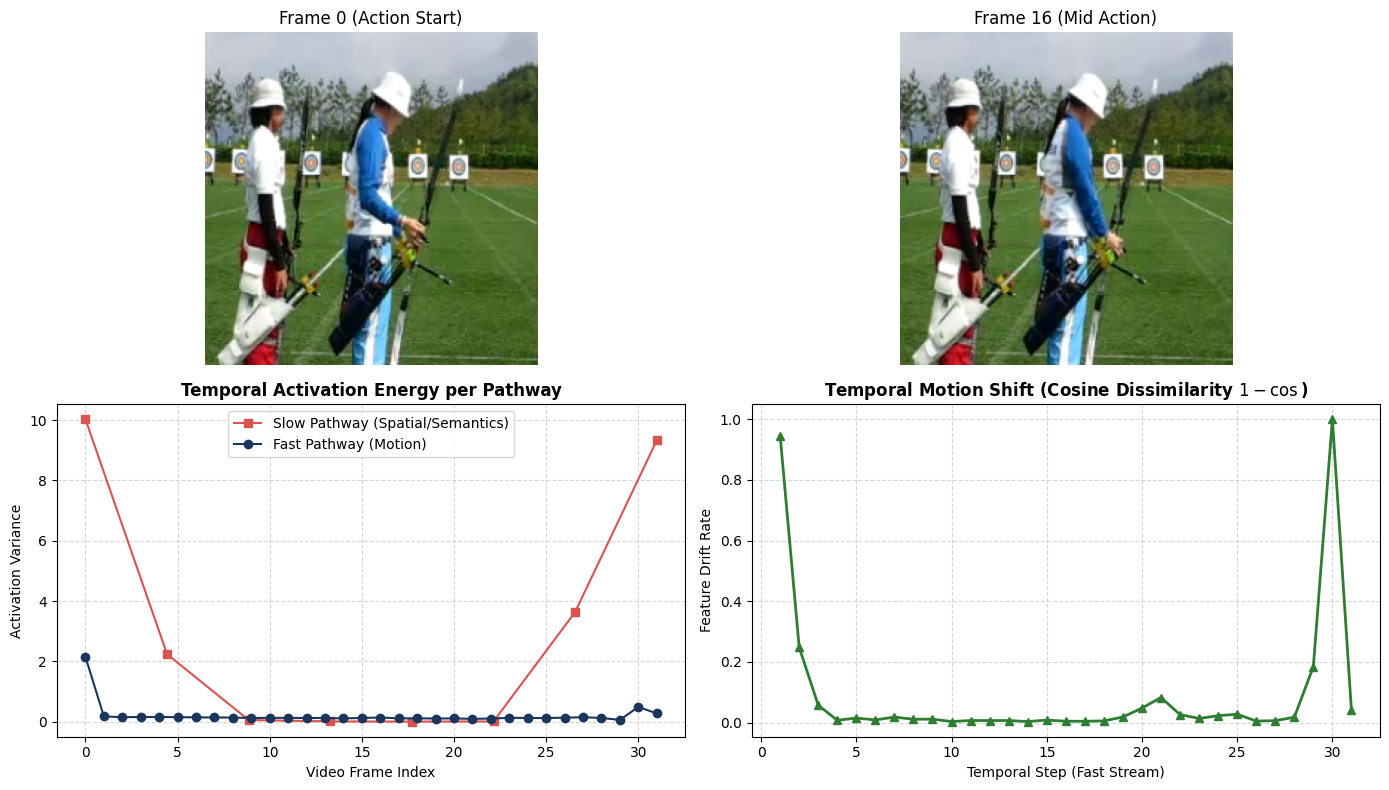

In [1]:
import sys
import subprocess

try:
    import pytorchvideo
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "pytorchvideo"])

import os
import cv2
import json
import urllib.request
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model = torch.hub.load(
    'facebookresearch/pytorchvideo:main', 
    'slowfast_r50', 
    pretrained=True
)
model = model.eval().to(device)

label_url = "https://dl.fbaipublicfiles.com/pyslowfast/dataset/class_names/kinetics_classnames.json"
label_path = "kinetics_classnames.json"
urllib.request.urlretrieve(label_url, label_path)

with open(label_path, "r") as f:
    kinetics_dict = json.load(f)

categories = {int(v): k for k, v in kinetics_dict.items()}

features = {}

def hook_slow(module, input, output):
    features['slow_features'] = output.detach()

def hook_fast(module, input, output):
    features['fast_features'] = output.detach()

model.blocks[4].multipathway_blocks[0].register_forward_hook(hook_slow)
model.blocks[4].multipathway_blocks[1].register_forward_hook(hook_fast)

sample_url = "https://dl.fbaipublicfiles.com/pytorchvideo/projects/archery.mp4"
sample_video = "sample_action.mp4"
urllib.request.urlretrieve(sample_url, sample_video)

cap = cv2.VideoCapture(sample_video)
raw_frames = []
while cap.isOpened() and len(raw_frames) < 64:
    ret, frame = cap.read()
    if not ret:
        break
    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frame = cv2.resize(frame, (256, 256))
    h, w, _ = frame.shape
    start_y, start_x = (h - 224) // 2, (w - 224) // 2
    raw_frames.append(frame[start_y:start_y + 224, start_x:start_x + 224])
cap.release()

clip_len = 32
frames_np = np.array(raw_frames[:clip_len])
if len(frames_np) < clip_len:
    raise ValueError(f"Video too short. Needed {clip_len} frames, got {len(frames_np)}.")

tensor_video = torch.from_numpy(frames_np).permute(3, 0, 1, 2).float() / 255.0
mean = torch.tensor([0.45, 0.45, 0.45]).view(3, 1, 1, 1)
std = torch.tensor([0.225, 0.225, 0.225]).view(3, 1, 1, 1)
normalized_video = (tensor_video - mean) / std

alpha = 4
fast_pathway = normalized_video.unsqueeze(0).to(device)
slow_indices = torch.linspace(0, clip_len - 1, clip_len // alpha).long()
slow_pathway = torch.index_select(normalized_video, 1, slow_indices).unsqueeze(0).to(device)
inputs = [slow_pathway, fast_pathway]

with torch.no_grad():
    predictions = model(inputs)
    probs = torch.softmax(predictions, dim=1).squeeze(0)

top5_probs, top5_indices = torch.topk(probs, 5)
print("\n================== TOP-5 PREDICTIONS ==================")
for i in range(5):
    idx = top5_indices[i].item()
    class_name = categories.get(idx, f"Class {idx}")
    print(f"{i+1}. {class_name}: {top5_probs[i].item() * 100:.2f}%")

slow_act = features['slow_features'][0]
fast_act = features['fast_features'][0]

slow_energy = torch.mean(torch.var(slow_act, dim=(2, 3)), dim=0).cpu().numpy()
fast_energy = torch.mean(torch.var(fast_act, dim=(2, 3)), dim=0).cpu().numpy()

fast_t = fast_act.shape[1]
fast_vectors = torch.mean(fast_act, dim=(2, 3)).T
cos = nn.CosineSimilarity(dim=1)

temporal_dissimilarity = [
    (1.0 - cos(fast_vectors[t].unsqueeze(0), fast_vectors[t + 1].unsqueeze(0)).item())
    for t in range(fast_t - 1)
]

fig, axs = plt.subplots(2, 2, figsize=(14, 8))

axs[0, 0].imshow(frames_np[0])
axs[0, 0].set_title("Frame 0 (Action Start)")
axs[0, 0].axis('off')

axs[0, 1].imshow(frames_np[clip_len // 2])
axs[0, 1].set_title(f"Frame {clip_len // 2} (Mid Action)")
axs[0, 1].axis('off')

axs[1, 0].plot(
    np.linspace(0, clip_len - 1, len(slow_energy)), slow_energy,
    label='Slow Pathway (Spatial/Semantics)', marker='s', color='#D9534F'
)
axs[1, 0].plot(
    np.linspace(0, clip_len - 1, len(fast_energy)), fast_energy,
    label='Fast Pathway (Motion)', marker='o', color='#1B365D'
)
axs[1, 0].set_title("Temporal Activation Energy per Pathway", fontweight='bold')
axs[1, 0].set_xlabel("Video Frame Index")
axs[1, 0].set_ylabel("Activation Variance")
axs[1, 0].legend()
axs[1, 0].grid(True, linestyle='--', alpha=0.5)

axs[1, 1].plot(range(1, fast_t), temporal_dissimilarity, color='#2E7D32', lw=2, marker='^')
axs[1, 1].set_title("Temporal Motion Shift (Cosine Dissimilarity $1 - \\cos$)", fontweight='bold')
axs[1, 1].set_xlabel("Temporal Step (Fast Stream)")
axs[1, 1].set_ylabel("Feature Drift Rate")
axs[1, 1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()